# Profile full Reddit file (HelpRoute go/no-go)
Chunked pass over `data/raw/reddit_posts.csv` (skips `comments`). Saves candidate posts to `data/processed/` so later steps don't re-read the 5 GB file.

In [1]:
import os, re, time
from collections import Counter
from pathlib import Path
import pandas as pd

PATH = os.environ.get("REDDIT_CSV", "data/raw/reddit_posts.csv")  # or set REDDIT_CSV
OUT = Path("data/processed")
OUT.mkdir(parents=True, exist_ok=True)
CHUNK = 50_000
COLS = ["post_id", "title", "description", "community_name", "date_posted",
        "num_comments", "num_upvotes", "locked_post"]

In [2]:
BAY_CITIES = [
    "san francisco", "oakland", "berkeley", "san jose", "fremont", "hayward", "richmond",
    "concord", "walnut creek", "antioch", "pittsburg", "vallejo", "fairfield", "vacaville",
    "santa rosa", "petaluma", "napa", "san rafael", "novato", "daly city", "san mateo",
    "redwood city", "palo alto", "mountain view", "sunnyvale", "santa clara", "milpitas",
    "cupertino", "south san francisco", "san leandro", "alameda", "union city", "newark",
    "pleasanton", "livermore", "dublin", "san ramon", "east palo alto", "gilroy", "morgan hill",
    "el cerrito", "emeryville", "san bruno", "pacifica", "martinez", "brentwood", "san pablo",
]
# longest first so "south san francisco" wins over "san francisco"
CITY_RE = re.compile(r"\b(" + "|".join(map(re.escape, sorted(BAY_CITIES, key=len, reverse=True))) + r")\b")

NEEDS = {
    "housing":   r"evict|eviction|landlord|behind on rent|can'?t (?:afford|pay) (?:my )?rent|3.day notice|rent increase",
    "homeless":  r"homeless|sleeping in (?:my|the) car|living in (?:my|a) car|shelter|couch.?surf",
    "food":      r"food bank|food stamps|calfresh|snap benefits|\bebt\b|can'?t afford (?:food|groceries)|hungry|pantry",
    "utilities": r"pg&?e|shut.?off|utility bill|electric bill|behind on bills",
    "medical":   r"medical bill|medical debt|uninsured|medi.?cal|\ber bill|hospital bill",
    "job_loss":  r"laid off|layoff|lost my job|got fired|hours (?:got )?cut|unemployment|\bedd\b",
    "debt_trap": r"payday loan|cash advance|overdraft|klarna|afterpay|affirm|collections|predatory",
}
URGENT = (r"tonight|tomorrow|this week|by friday|by monday|3.day notice|"
          r"no food|nowhere to (?:go|sleep)|shut.?off (?:notice|tomorrow)|eviction notice")
TARGET_SUBS = ["bayarea", "sanfrancisco", "oakland", "berkeley", "sanjose", "eastbay",
               "housing", "povertyfinance", "personalfinance", "frugal", "homeless",
               "antiwork", "jobs", "careerguidance", "recruitinghell"]
BAY_SUBS = {"bayarea", "sanfrancisco", "oakland", "berkeley", "sanjose", "eastbay"}
AMBIGUOUS = {"richmond", "dublin", "concord", "newark", "san jose", "alameda", "fremont",
             "pittsburg", "brentwood", "union city", "fairfield", "martinez", "berkeley",
             "san mateo", "santa clara", "hayward", "livermore", "novato", "napa"}
BAY_CONTEXT_RE = re.compile(r"bay area|\bsf\b|california|\bca\b|east bay|south bay|peninsula|silicon valley")

In [3]:
rows = removed = 0
sub_counts, month_counts, locked, city_counts = Counter(), Counter(), Counter(), Counter()
need_counts, need_by_sub = Counter(), Counter()
keep = []
t0 = time.time()

def bay_cities(t, sub):
    cities = set(CITY_RE.findall(t))
    if cities and sub not in BAY_SUBS and not BAY_CONTEXT_RE.search(t):
        cities -= AMBIGUOUS  # e.g. Richmond VA, Dublin Ireland
    return ";".join(sorted(cities))

reader = pd.read_csv(PATH, usecols=lambda c: c in COLS, chunksize=CHUNK, dtype=str, on_bad_lines="skip")
for i, ch in enumerate(reader):
    ch = ch.fillna({"title": "", "description": "", "community_name": "?", "date_posted": "?", "locked_post": "NA"})
    rows += len(ch)
    sub = ch["community_name"].str.lower()
    sub_counts.update(sub)
    month_counts.update(ch["date_posted"].str[:7])
    locked.update(ch["locked_post"])
    removed += ch["description"].str.contains(r"^\[(?:removed|deleted)\]").sum()

    text = (ch["title"] + " " + ch["description"]).str.lower().str.replace("\u2019", "'")
    hits = pd.DataFrame({k: text.str.contains(rx) for k, rx in NEEDS.items()})
    ch["needs"] = [";".join(k for k, v in zip(NEEDS, r) if v) for r in hits.to_numpy()]
    ch["any_need"] = hits.any(axis=1)
    ch["urgent_kw"] = text.str.contains(URGENT)
    ch["cities"] = [bay_cities(t, s) for t, s in zip(text, sub)]
    ch["bay"] = (ch["cities"] != "") | sub.isin(BAY_SUBS)

    need_counts.update(hits.sum().to_dict())
    for k in NEEDS:
        need_by_sub.update((s, k) for s in sub[hits[k]])
    for c in ch["cities"]:
        if c:
            city_counts.update(c.split(";"))

    mask = ch["any_need"] | ch["bay"] | sub.isin(TARGET_SUBS)
    keep.append(ch[mask])
    if i % 10 == 0:
        print(f"chunk {i}: {rows:,} rows, {time.time()-t0:.0f}s")

cand = pd.concat(keep, ignore_index=True)
print(f"done: {rows:,} rows in {time.time()-t0:.0f}s; candidates kept: {len(cand):,}")

chunk 0: 50,000 rows, 35s


done: 230,520 rows in 157s; candidates kept: 69,266


In [4]:
print(f"TOTAL ROWS: {rows:,}   removed/deleted bodies: {removed:,}")
print(f"posts mentioning a Bay Area city: {(cand['cities'] != '').sum():,}")
print(f"unique subreddits: {len(sub_counts):,}")
print("\nTOP 40 SUBREDDITS:")
for s, n in sub_counts.most_common(40):
    print(f"  {s:30s} {n:,}")
print("\nlocked_post values:", dict(locked))

TOTAL ROWS: 230,520   removed/deleted bodies: 4,004
posts mentioning a Bay Area city: 6,535
unique subreddits: 793

TOP 40 SUBREDDITS:
  personalfinance                15,059
  trueunpopularopinion           10,362
  amitheasshole                  9,106
  personalfinancecanada          8,631
  recruitinghell                 6,210
  povertyfinance                 5,691
  worldnews                      5,644
  changemyview                   5,443
  ukpersonalfinance              5,441
  unpopularopinion               5,435
  newsph                         4,253
  frugal                         4,200
  trueoffmychest                 4,088
  housinguk                      4,052
  antiwork                       4,047
  sanfrancisco                   4,004
  careerguidance                 3,812
  personalfinanceindia           3,779
  bayarea                        3,658
  jobs                           3,634
  ukjobs                         2,805
  news                           2,475
  nof

2025-01     1756
2025-02     1646
2025-03     1950
2025-04     2322
2025-05     3000
2025-06     4970
2025-07     5618
2025-08     8009
2025-09     7905
2025-10     6485
2025-11     5148
2025-12     5740
2026-01     6196
2026-02     7394
2026-03    14944
2026-04    18406
2026-05    21226
2026-06    22972
2026-07    25055
2026-08    23260
2026-09    23058
2026-10    12561
2026-11      899


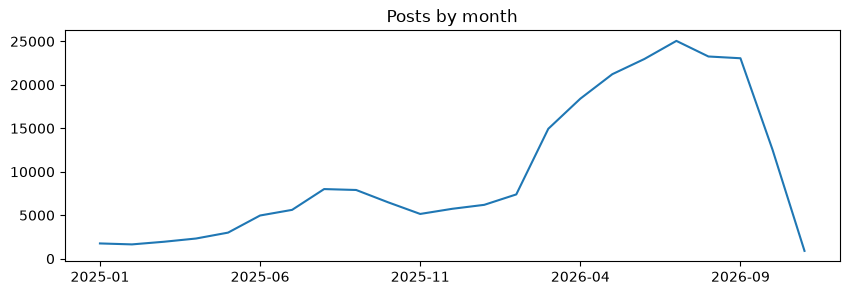

In [5]:
months = pd.Series(month_counts).sort_index()
print(months.to_string())
months[months.index.str.match(r"^\d{4}-\d{2}$")].plot(figsize=(10, 3), title="Posts by month");

In [6]:
print("TOP 25 CITIES MENTIONED:")
for c, n in city_counts.most_common(25):
    print(f"  {c:22s} {n:,}")
print("\nNEED KEYWORD HITS (rough upper bound, not labels):")
for k, n in need_counts.most_common():
    print(f"  {k:10s} {n:,}")
print("\nNEED HITS BY SUBREDDIT (top 30 pairs):")
for (s, k), n in need_by_sub.most_common(30):
    print(f"  {s:25s} {k:10s} {n:,}")

TOP 25 CITIES MENTIONED:
  oakland                2,051
  san francisco          1,767
  san jose               1,127
  berkeley               731
  santa clara            302
  alameda                207
  sunnyvale              200
  richmond               173
  palo alto              165
  san mateo              157
  fremont                152
  mountain view          121
  walnut creek           113
  cupertino              101
  milpitas               96
  emeryville             93
  hayward                89
  dublin                 82
  redwood city           74
  san leandro            74
  pleasanton             71
  concord                68
  daly city              63
  napa                   54
  south san francisco    44

NEED KEYWORD HITS (rough upper bound, not labels):
  job_loss   5,722
  medical    4,991
  housing    3,381
  homeless   3,141
  debt_trap  2,062
  food       1,754
  utilities  750

NEED HITS BY SUBREDDIT (top 30 pairs):
  personalfinance           medi

In [7]:
def check(name, value, go, maybe):
    status = "GO" if value >= go else ("MAYBE" if value >= maybe else "NO")
    print(f"  [{status:5s}] {name}: {value:,}  (GO >= {go:,}, MAYBE >= {maybe:,})")
    return status

print("TARGET SUBREDDITS PRESENT:")
for s in TARGET_SUBS:
    print(f"  {s:18s} {sub_counts.get(s, 0):,}")

need = cand[cand["any_need"]]
print("\n=== GO / NO-GO FOR HELPROUTE ===")
results = [
    check("posts with any need keyword", len(need), 3000, 1000),
    check("Bay Area need posts (city mention or Bay sub)", int(need["bay"].sum()), 500, 150),
    check("need posts with urgency words", int(need["urgent_kw"].sum()), 300, 100),
    check("posts in target subreddits", sum(sub_counts.get(s, 0) for s in TARGET_SUBS), 20000, 5000),
]
weak = [k for k in NEEDS if need_counts[k] < 150]
print(f"  need labels with <150 hits (merge or drop): {weak or 'none'}")
verdict = ("GO - enough data for HelpRoute as planned." if all(r == "GO" for r in results)
           else "NO-GO for full HelpRoute - consider backup ideas." if "NO" in results
           else "MAYBE - doable with reduced scope.")
print("\nVERDICT:", verdict)

TARGET SUBREDDITS PRESENT:
  bayarea            3,658
  sanfrancisco       4,004
  oakland            977
  berkeley           653
  sanjose            2,303
  eastbay            510
  housing            0
  povertyfinance     5,691
  personalfinance    15,059
  frugal             4,200
  homeless           612
  antiwork           4,047
  jobs               3,634
  careerguidance     3,812
  recruitinghell     6,210

=== GO / NO-GO FOR HELPROUTE ===
  [GO   ] posts with any need keyword: 19,751  (GO >= 3,000, MAYBE >= 1,000)
  [GO   ] Bay Area need posts (city mention or Bay sub): 1,086  (GO >= 500, MAYBE >= 150)
  [GO   ] need posts with urgency words: 1,405  (GO >= 300, MAYBE >= 100)
  [GO   ] posts in target subreddits: 55,370  (GO >= 20,000, MAYBE >= 5,000)
  need labels with <150 hits (merge or drop): none

VERDICT: GO - enough data for HelpRoute as planned.


In [8]:
cand.to_parquet(OUT / "reddit_candidates.parquet", index=False)
print("saved", OUT / "reddit_candidates.parquet", cand.shape)
n = min(10, int(cand["any_need"].sum()))
cand[cand["any_need"]].sample(n, random_state=0)[["community_name", "title", "needs", "cities"]]

saved data\processed\reddit_candidates.parquet (69266, 13)


,community_name,title,needs,cities
25818,PersonalFinanceCanada,Does the math actually favor diligent index in...,homeless,
7990,TrueOffMyChest,I'm considering just leaving before I drown more,utilities,
15866,SoftwareEngineerJobs,I got fired after reporting my manager's behav...,job_loss,
39445,fednews,Unique Situation Enrollment (Health Insurance),medical;debt_trap,
31055,UKHousing,Imagine applying to rent your own flat because...,housing,
13914,OaklandCA,"Why does Oakland have more illegal dumping, tr...",homeless,oakland
22192,recruitinghell,Young Graduates Employment Crisis,job_loss,
62050,personalfinance,Need financial advice for pet emergencies,medical,
34814,JobsInDubaiUAE,FIELD SALES OPPORTUNITY — DUBAI & ABU DHABI,food,
27243,SanJose,I found a Bearded dragon at Oakridge Mall,food,san jose


## Clean candidate posts
Drop deleted posts, duplicates, and news/opinion/off-topic subreddits; normalize text; redo keyword flags; tag region.

In [9]:
import html

df = pd.read_parquet(OUT / "reddit_candidates.parquet")
df["sub"] = df["community_name"].str.lower()
log = [("candidates", len(df))]

def step(name, mask):
    global df
    df = df[mask].copy()
    log.append((name, len(df)))

In [10]:
QUOTES = str.maketrans({"\u2019": "'", "\u2018": "'", "\u201c": '"', "\u201d": '"',
                        "\u2013": "-", "\u2014": "-", "\u00a0": " "})

def clean_text(s):
    s = html.unescape(s).translate(QUOTES)
    s = re.sub(r"https?://\S+", "[url]", s)
    return re.sub(r"\s+", " ", s).strip()

df["title"] = df["title"].map(clean_text)
df["description"] = df["description"].map(clean_text)

In [11]:
step("removed/deleted/link-only body", ~df["description"].str.match(r"^\[[^\]]{1,20}\]$"))

In [12]:
DROP_SUB_RE = r"(?<!newport)news|politic|opinion|changemyview"
DROP_SUBS = {"sanjosesharks", "oaklandathletics", "sanfranciscoweddings", "frugalmalefashion"}
print("dropping:", sorted(df.loc[df["sub"].str.contains(DROP_SUB_RE) | df["sub"].isin(DROP_SUBS), "sub"].unique()))
step("news/opinion/off-topic subs", ~df["sub"].str.contains(DROP_SUB_RE) & ~df["sub"].isin(DROP_SUBS))

dropping: ['abovethenormnews', 'ai_news_byte_sized', 'aidaily_news', 'aidevelopernews', 'ainewsandtrends', 'ainewsminute', 'animenews', 'anythinggoesnews', 'atlnews', 'ausnewstoday', 'ausnewswire', 'bollynewsandgossips', 'brandnewsentence', 'breakinguknews', 'businesstodaynews', 'canadanews', 'canadiannews', 'changemyview', 'changemyviewvn', 'chicagonewsgroup', 'chunews', 'citizenwatchnews', 'climatenews', 'conservativenewsweb', 'cosmicbooknews', 'cybernews', 'dailynewshungary', 'depropagandizednews', 'doctorwhonews', 'donaldtrumpnewss', 'environmentalnews', 'fednews', 'fishnews', 'foodnews', 'foxnews', 'frugalmalefashion', 'full_news', 'fussballwm2026news', 'gamernews', 'gamingnews', 'gamingnewsandleaks', 'gbnews', 'global_news_hub', 'globalnews', 'globalnewsuncensored', 'goodnews', 'goodnewsuk', 'hanzalanews', 'hockeynews', 'hotsciencenews', 'id_news', 'indianews', 'indianews247', 'indianewspaperjobs', 'inindiannews', 'insnipnews', 'interestingnewsworld', 'internationalnews', 'inthen

In [13]:
df["text"] = (df["title"] + " " + df["description"]).str.strip()
df = df.sort_values("date_posted")
key = (df["text"].str.lower().str.replace(r"[^a-z0-9 ]", "", regex=True)
       .str.replace(r"\s+", " ", regex=True))
step("duplicates (kept earliest)", ~key.duplicated())

df["n_words"] = df["text"].str.split().str.len()
step("fewer than 5 words", df["n_words"] >= 5)
df["text"] = [" ".join(t.split()[:400]) for t in df["text"]]

In [14]:
BAY_SUBS |= {"oaklandca", "berkeleyca", "oaklandfood", "bayarearealestate", "almosthomeless_bayarea"}
low = df["text"].str.lower()
hits = pd.DataFrame({k: low.str.contains(rx) for k, rx in NEEDS.items()}, index=df.index)
df["needs"] = [";".join(k for k, v in zip(NEEDS, r) if v) for r in hits.to_numpy()]
df["any_need"] = hits.any(axis=1)
df["urgent_kw"] = low.str.contains(URGENT)
df["cities"] = [bay_cities(t, s) for t, s in zip(low, df["sub"])]
df["bay"] = (df["cities"] != "") | df["sub"].isin(BAY_SUBS)

NON_US = (r"uk|canada|india|_ind$|ph$|philippines|aus(?!tin)|nz$|ireland|irish|germany|swiss|italia|^eu|"
          r"japan|singapore|uae|za$|montreal|toronto|vancouver|netherlands")
df["region"] = "us_or_unknown"
df.loc[df["sub"].str.contains(NON_US), "region"] = "non_us"
df.loc[df["bay"], "region"] = "bay_area"

In [15]:
# Keep: all posts in the 6 Bay Area subs + posts in housing/money and work subs that mention a Bay Area city
GROUPS = {
    "bay_local":     ["bayarea", "sanfrancisco", "oakland", "berkeley", "sanjose", "eastbay"],
    "housing_money": ["housing", "povertyfinance", "personalfinance", "frugal", "homeless"],
    "work":          ["antiwork", "jobs", "careerguidance", "recruitinghell"],
}
df["sub_group"] = df["sub"].map({s: g for g, subs in GROUPS.items() for s in subs})
step("only the 15 chosen subreddits", df["sub_group"].notna())
step("non-Bay subs must mention a Bay Area city", (df["sub_group"] == "bay_local") | (df["cities"] != ""))
print(df.groupby("sub_group").agg(posts=("post_id", "size"), need_posts=("any_need", "sum")))

               posts  need_posts
sub_group                       
bay_local      11713         836
housing_money     35          10
work              27           6


In [16]:
print(pd.DataFrame(log, columns=["step", "rows_left"]).to_string(index=False))
print(df["region"].value_counts().to_string())
print(f"need posts: {df['any_need'].sum():,}   Bay Area need posts: {(df['any_need'] & df['bay']).sum():,}")
print("non-US subs (check this list):", sorted(df.loc[df["region"] == "non_us", "sub"].unique()))

cols = ["post_id", "community_name", "sub", "date_posted", "num_comments", "num_upvotes", "text",
        "n_words", "needs", "any_need", "urgent_kw", "cities", "bay", "region", "sub_group"]
df[cols].to_parquet(OUT / "reddit_clean.parquet", index=False)
df.sample(15, random_state=1)[["sub", "sub_group", "cities", "needs", "text"]]

                                     step  rows_left
                               candidates      69266
           removed/deleted/link-only body      68148
              news/opinion/off-topic subs      64455
               duplicates (kept earliest)      61715
                       fewer than 5 words      61469
            only the 15 chosen subreddits      52087
non-Bay subs must mention a Bay Area city      11775
region
bay_area    11775
need posts: 852   Bay Area need posts: 852
non-US subs (check this list): []


,sub,sub_group,cities,needs,text
69175,oakland,bay_local,,,Tires Needing Air Is there a place that checks...
16242,sanjose,bay_local,,,Large number of unregistered Priuses parked on...
45855,sanjose,bay_local,palo alto,,Went to the Beeple Node Exhibit I randomly saw...
47344,bayarea,bay_local,,,California strips Bay Area city [Bridbane] of ...
11488,sanfrancisco,bay_local,,,Lenticular clouds over SF great cloudscape ! i...
10140,bayarea,bay_local,,,Claude the Alligator Plushy This is a long sho...
8530,sanfrancisco,bay_local,,,Franklin St strikes again At least no one happ...
45214,sanfrancisco,bay_local,,,Found a bike messenger calendar from 2007 Reme...
59776,bayarea,bay_local,,,What a deal from Expedia! It's even 76% less t...
27167,bayarea,bay_local,,,How often do you choose not to do something be...


## Zero-shot screen (Hugging Face, baseline B2)
BART-MNLI scores each keyword-flagged post 0-1: real need vs. question/news. Used as-is (not our model). Don't use it to filter the labeling pool.

In [ ]:
import torch
from transformers import pipeline

LIMIT = None  # e.g. 200 for a quick run; None = all flagged posts
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print("device:", DEVICE)  # cpu is slow (~30+ min for ~850 posts); GPU/mps is minutes

zs = pd.read_parquet(OUT / "reddit_clean.parquet")
zs = zs[zs["any_need"]].copy()
if LIMIT:
    zs = zs.sample(min(LIMIT, len(zs)), random_state=0)

clf = pipeline("zero-shot-classification", model="facebook/bart-large-mnli", device=DEVICE)
LABELS = ["someone who cannot afford or is losing housing, food, utilities, medical care, or income",
          "a general question, news, opinion, or discussion"]

In [ ]:
texts = [" ".join(t.split()[:200]) for t in zs["text"]]
scores, t0 = [], time.time()
for i in range(0, len(texts), 16):
    res = clf(texts[i:i + 16], candidate_labels=LABELS,
              hypothesis_template="This post is from {}.", truncation=True)
    scores += [dict(zip(r["labels"], r["scores"]))[LABELS[0]] for r in res]
    el = time.time() - t0
    print(f"\r{len(scores)}/{len(texts)}  {el:.0f}s  ETA {el / len(scores) * (len(texts) - len(scores)):.0f}s", end="")

zs["zs_need_score"] = scores
zs[["post_id", "sub", "needs", "cities", "urgent_kw", "zs_need_score", "text"]].to_parquet(
    OUT / "zeroshot_flagged.parquet", index=False)
print("\nsaved", OUT / "zeroshot_flagged.parquet")

In [ ]:
print(f"scored as real need (> 0.5): {(zs['zs_need_score'] > 0.5).mean():.0%} of {len(zs)} keyword-flagged posts")
zs["zs_need_score"].plot.hist(bins=20, figsize=(8, 3), title="Zero-shot need score");

In [ ]:
share = lambda s: (s > 0.5).mean()
by_need = zs.assign(need=zs["needs"].str.split(";")).explode("need")
print(by_need.groupby("need")["zs_need_score"].agg(posts="size", real_need_share=share)
      .sort_values("posts", ascending=False).round(2))
print()
print(zs.groupby("sub")["zs_need_score"].agg(posts="size", real_need_share=share)
      .sort_values("posts", ascending=False).round(2))

In [ ]:
pd.set_option("display.max_colwidth", 200)
show = lambda d: d[["sub", "needs", "zs_need_score"]].assign(text=d["text"].str[:200])
print("HIGHEST (most need-like)"); display(show(zs.nlargest(10, "zs_need_score")))
print("LOWEST (most question/news-like)"); display(show(zs.nsmallest(10, "zs_need_score")))
mid = zs[zs["zs_need_score"].between(0.4, 0.6)]
print("BORDERLINE 0.4-0.6"); display(show(mid.sample(min(10, len(mid)), random_state=0)))

Hand-check: fill `human_real_need` (1/0) in the CSV using the labeling guide, then run the next cell.

In [ ]:
HC = OUT / "zeroshot_handcheck.csv"
if not HC.exists():
    zs.sample(min(30, len(zs)), random_state=1)[["post_id", "sub", "needs", "zs_need_score", "text"]].assign(human_real_need="").to_csv(HC, index=False)
    print("wrote", HC, "- fill human_real_need, then rerun this cell")
else:
    hc = pd.read_csv(HC).dropna(subset=["human_real_need"])
    agree = ((hc["zs_need_score"] > 0.5).astype(int) == hc["human_real_need"].astype(int)).mean()
    print(f"{len(hc)} hand-checked: zero-shot agrees with human {agree:.0%}; "
          f"humans say real need for {hc['human_real_need'].mean():.0%}")